
🔹 Eksik Veri Özeti:
 echocardiography_ef            388
mallampati_score               332
crp                            325
LAKTAT_LDH                     315
hco3                           266
pco2                           260
po2                            260
ph                             254
desaturation_index             212
chloride                       202
calcium                        191
potassium                      182
minimum_oxygen_saturation      180
avg_oxygen_percent             180
sodium                         178
pack_years                     163
folate                         139
st3                            136
ferritin                       131
ahi_index                      126
vitamin_b12                    118
st4                            116
hip_circumference              102
tsh                            101
head_circumference             100
waist_circumference             98
neck_circumference              98
epworth_score                   9

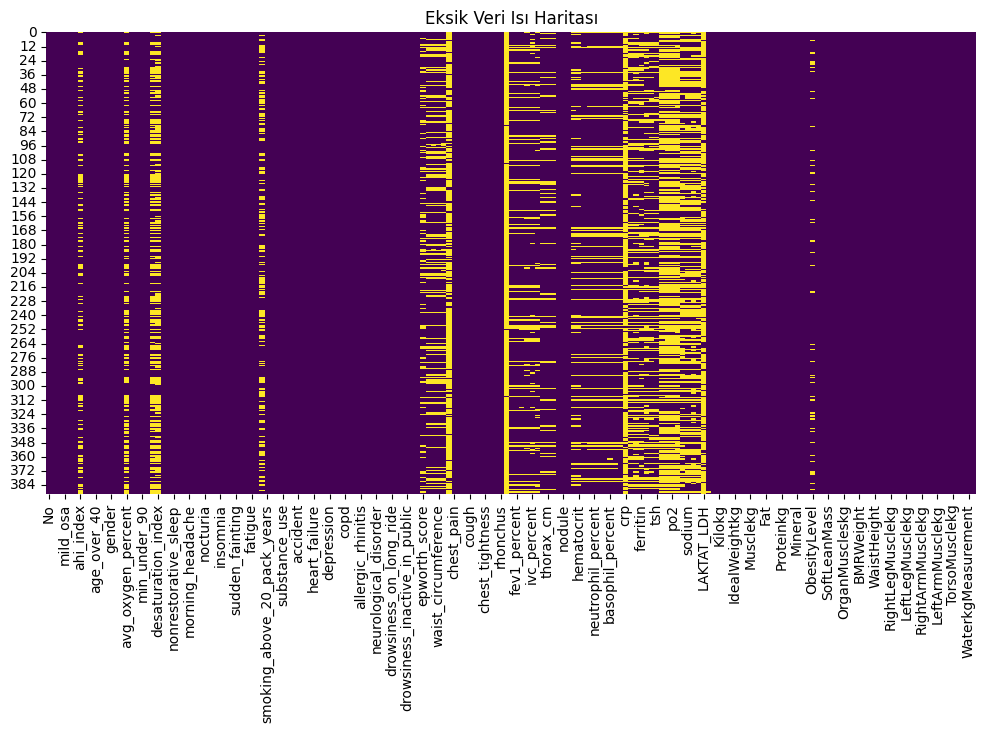


🔹 Sayısal Değişken İstatistikleri:
                     count        mean         std    min      25%      50%  \
No                  392.0  196.581633  113.439680   1.00  98.7500  196.500   
simple_snoring      392.0    0.081633    0.274154   0.00   0.0000    0.000   
mild_osa            392.0    0.132653    0.339633   0.00   0.0000    0.000   
moderate_osa        392.0    0.122449    0.328223   0.00   0.0000    0.000   
severe_osa          392.0    0.362245    0.481263   0.00   0.0000    0.000   
...                   ...         ...         ...    ...      ...      ...   
TorsoMusclekg       392.0   31.617602    5.820637  12.10  27.1000   31.300   
Weightkg_A          392.0   88.215561   18.405689  41.60  75.6000   87.100   
LeankgMeasurement   392.0   61.162985   12.336967  34.09  51.1100   60.820   
WaterkgMeasurement  392.0   44.455255    8.677938  23.96  37.4425   44.185   
FatkgMeasurement    392.0   27.052883   11.982846   3.03  18.3375   25.205   

                         7

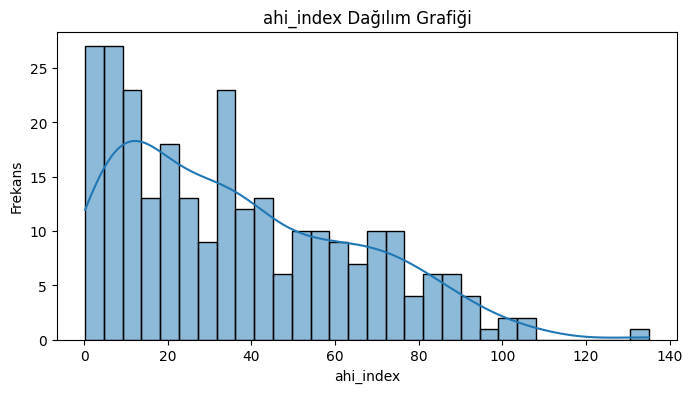

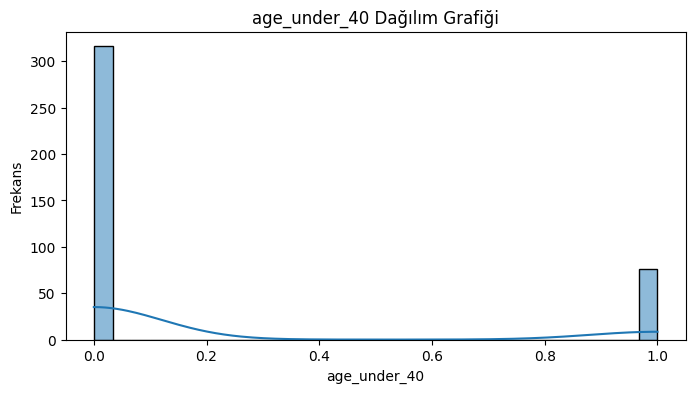

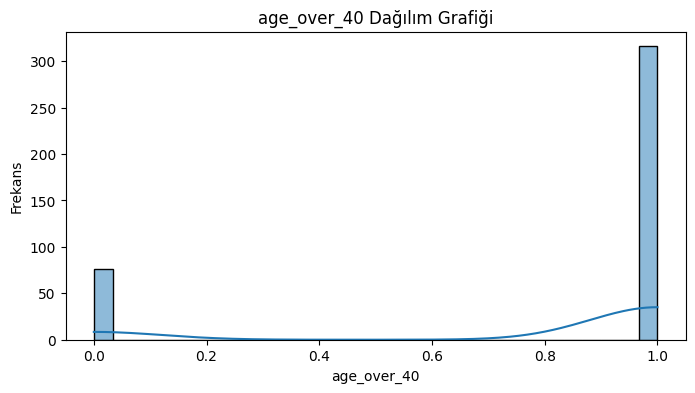

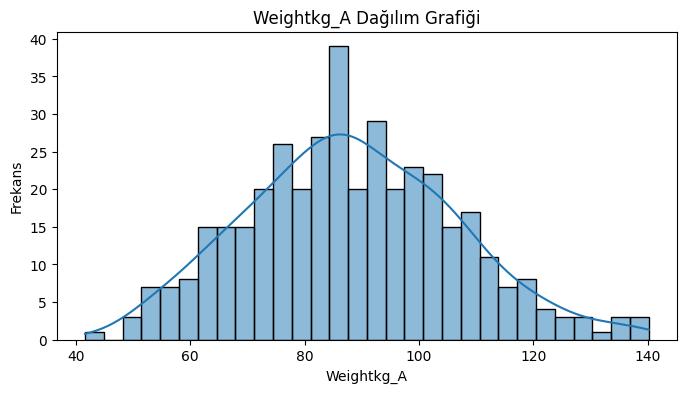

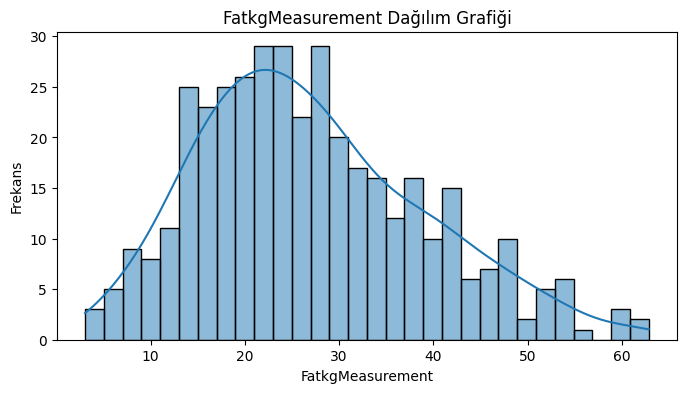

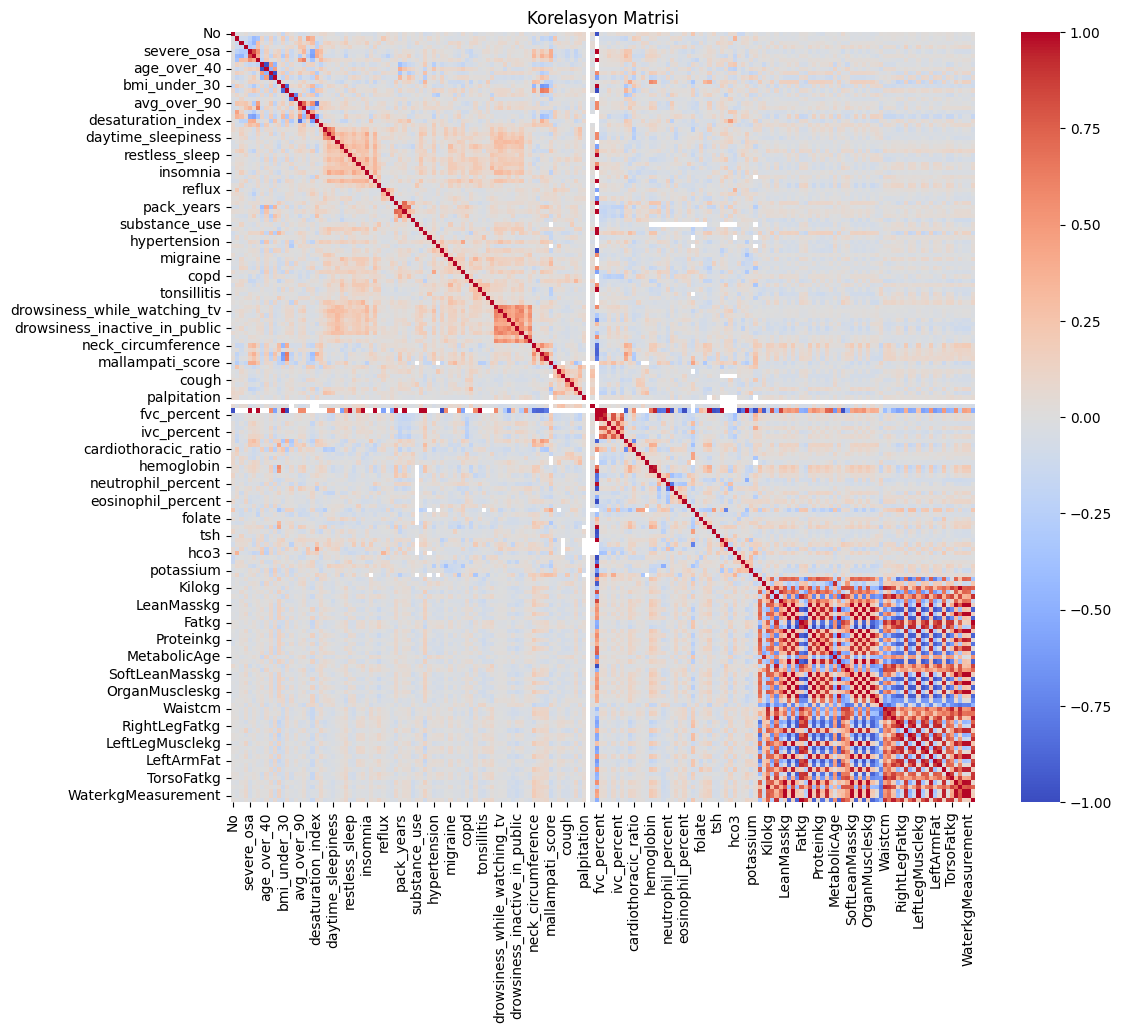

In [3]:
# ===========================
# 📌 GEREKLİ KÜTÜPHANELER
# ===========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ===========================
# 📌 VERİ YÜKLEME
# ===========================
file_path = "Amsa_Tez_Verileri (2)4.xlsx"
df = pd.read_excel(file_path, sheet_name='Amsa_Tez_Verileri (2)4')

# ===========================
# 📌 EKSİK VERİ ANALİZİ
# ===========================
missing_summary = df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)
print("\n🔹 Eksik Veri Özeti:\n", missing_summary)

# Eksik veri ısı haritası
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Eksik Veri Isı Haritası")
plt.show()

# ===========================
# 📌 SAYISAL DEĞİŞKENLERİN TEMEL İSTATİSTİKLERİ
# ===========================
desc = df.describe().T
print("\n🔹 Sayısal Değişken İstatistikleri:\n", desc)

# ===========================
# 📌 AYKIRI DEĞER ANALİZİ (IQR YÖNTEMİ)
# ===========================
outlier_counts = {}
for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    if not outliers.empty:
        outlier_counts[col] = outliers.shape[0]

outlier_df = pd.DataFrame.from_dict(outlier_counts, orient='index', columns=['Aykırı Değer Sayısı'])
outlier_df = outlier_df.sort_values(by='Aykırı Değer Sayısı', ascending=False)
print("\n🔹 Aykırı Değer Sayıları:\n", outlier_df)

# ===========================
# 📌 ÖNEMLİ DEĞİŞKENLERDE DAĞILIM GRAFİKLERİ
# ===========================
selected_cols = ['ahi_index', 'age_under_40', 'age_over_40', 'Weightkg_A', 'FatkgMeasurement']

for col in selected_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"{col} Dağılım Grafiği")
    plt.xlabel(col)
    plt.ylabel("Frekans")
    plt.show()

# ===========================
# 📌 KORELASYON MATRİSİ (DÜZELTİLMİŞ)
# ===========================
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include='number')   # SADECE SAYISAL SÜTUNLARI AL
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title("Korelasyon Matrisi")
plt.show()
